In [29]:
!pip install pandas
!pip install seaborn
!pip install statistics

Defaulting to user installation because normal site-packages is not writeable
Defaulting to user installation because normal site-packages is not writeable
Defaulting to user installation because normal site-packages is not writeable


In [58]:
import pandas as pd
import seaborn as srn

In [31]:
dataset = pd.read_csv( r"C:\Users\mateus_s_cavalheiro\Documents\GitHub\projeto-integrador\dados_sensores_metaltech.csv")
dataset.head()

,timestamp,id_maquina,temperatura_c,vibracao_mm_s,pressao_bar,falha_motor
0,2026-01-01 00:00:00,M03,67.015129,1.523088,40.672538,0
1,2026-01-01 00:01:00,M04,58.048478,2.738448,38.644490,0
2,2026-01-01 00:02:00,M01,67.938896,2.566715,46.814723,0
3,2026-01-01 00:03:00,M03,74.567369,3.174506,35.055251,0
4,2026-01-01 00:04:00,M03,72.688150,4.642862,42.926834,0


In [32]:
dataset.shape

(10000, 6)

In [33]:
dataset.columns = ["Data/Hora", "Id_Maquina", "Temperatura_C", "Vibracao_mms", "Pressao_bar", "Falha_motor"]

In [34]:
dataset.head()

,Data/Hora,Id_Maquina,Temperatura_C,Vibracao_mms,Pressao_bar,Falha_motor
0,2026-01-01 00:00:00,M03,67.015129,1.523088,40.672538,0
1,2026-01-01 00:01:00,M04,58.048478,2.738448,38.644490,0
2,2026-01-01 00:02:00,M01,67.938896,2.566715,46.814723,0
3,2026-01-01 00:03:00,M03,74.567369,3.174506,35.055251,0
4,2026-01-01 00:04:00,M03,72.688150,4.642862,42.926834,0


In [35]:
dataset['Temperatura_C'].describe()

count    9704.000000
mean       81.217879
std        94.196943
min        50.387999
25%        66.845771
50%        70.343967
75%        74.101811
max       999.900000
Name: Temperatura_C, dtype: float64

In [37]:
dataset['Vibracao_mms'].describe()

count    9701.000000
mean        2.917828
std         5.825520
min       -50.000000
25%         2.666760
50%         3.025045
75%         3.408941
max        21.386227
Name: Vibracao_mms, dtype: float64

In [38]:
dataset['Pressao_bar'].describe()

count    9700.000000
mean       41.689877
std         8.231972
min        26.603188
25%        38.020922
50%        40.200918
75%        42.378051
max       102.177445
Name: Pressao_bar, dtype: float64

In [42]:
mediana_temp = dataset['Temperatura_C'].median()
dataset.loc[(dataset['Temperatura_C'] > 80), 'Temperatura_C'] = mediana_temp
dataset.loc[(dataset['Temperatura_C'].isnull()), 'Temperatura_C'] = mediana_temp

In [43]:
mediana_vibracao = dataset['Vibracao_mms'].median()
dataset.loc[(dataset['Vibracao_mms'] > 5) | (dataset['Vibracao_mms'] < 2), 'Vibracao_mms'] = mediana_vibracao
dataset.loc[(dataset['Vibracao_mms'].isnull()), 'Vibracao_mms'] = mediana_vibracao

In [44]:
mediana_pressao = dataset['Pressao_bar'].median()
dataset.loc[(dataset['Pressao_bar'] > 45), 'Pressao_bar'] = mediana_pressao
dataset.loc[(dataset['Pressao_bar'].isnull()), 'Pressao_bar'] = mediana_pressao

In [46]:
dataset[['Temperatura_C','Vibracao_mms','Pressao_bar']].describe()

,Temperatura_C,Vibracao_mms,Pressao_bar
count,10000.000000,10000.000000,10000.000000
mean,69.734479,3.029716,39.715970
std,4.465912,0.444036,2.557321
min,50.387999,2.000456,26.603188
25%,66.946068,2.730582,38.109003
50%,70.343967,3.025045,40.200918
75%,72.579129,3.307385,41.422659
max,79.970619,4.971166,44.999832


In [47]:
dataset.isnull().sum()

Data/Hora        0
Id_Maquina       0
Temperatura_C    0
Vibracao_mms     0
Pressao_bar      0
Falha_motor      0
dtype: int64

Text(0.5, 1.0, 'Temperatura em C°')

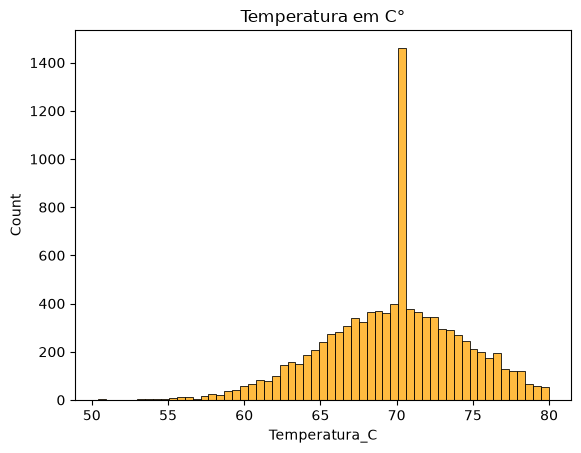

In [49]:
srn.histplot(dataset['Temperatura_C'], color = 'orange').set_title('Temperatura em C°')

Text(0.5, 1.0, 'Vibração em milimetros por segundos')

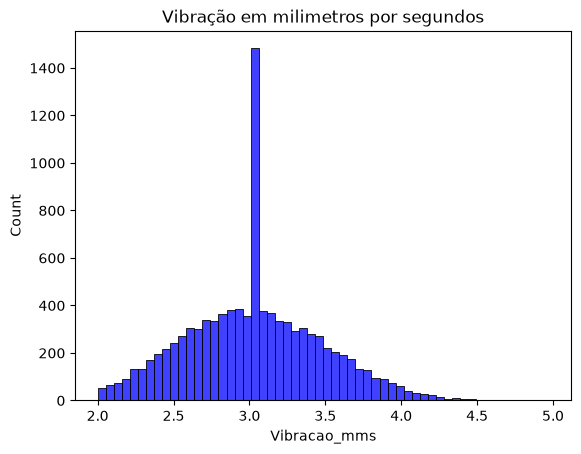

In [ ]:
srn.histplot(dataset['Vibracao_mms'], color = 'blue').set_title('Vibração em milimetros por segundos')

Text(0.5, 1.0, 'Pressão em "bar"')

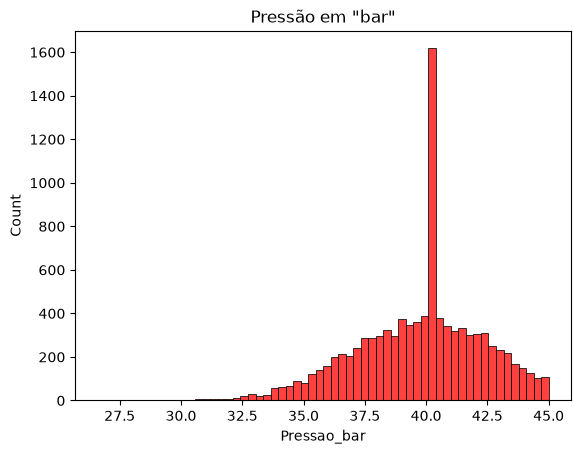

In [53]:
srn.histplot(dataset['Pressao_bar'], color = 'red').set_title('Pressão em "bar"')

In [54]:
dataset

,Data/Hora,Id_Maquina,Temperatura_C,Vibracao_mms,Pressao_bar,Falha_motor
0,2026-01-01 00:00:00,M03,67.015129,3.025045,40.672538,0
1,2026-01-01 00:01:00,M04,58.048478,2.738448,38.644490,0
2,2026-01-01 00:02:00,M01,67.938896,2.566715,40.200918,0
3,2026-01-01 00:03:00,M03,74.567369,3.174506,35.055251,0
4,2026-01-01 00:04:00,M03,72.688150,4.642862,42.926834,0
...,...,...,...,...,...,...
9995,2026-01-07 22:35:00,M04,66.077165,2.438983,37.834852,0
9996,2026-01-07 22:36:00,M03,76.041616,2.817291,36.478800,0
9997,2026-01-07 22:37:00,M02,71.223923,2.198480,39.862766,0
9998,2026-01-07 22:38:00,M02,73.060784,3.025045,37.422342,0


In [57]:
dataset.to_csv('dados_limpos.csv', index=False, sep=';', encoding='utf=8')